# Ensemble Learning for Sri Lankan Used-Vehicle Price Prediction
### Bagging vs Boosting vs Stacking vs Hybrid (RF + ANN)

**Module:** Hands-On Ensemble Learning Project  
**Dataset:** 10,388 vehicle adverts scraped from **ikman.lk**, Sri Lanka's largest classifieds site (57 brands, 473 models, manufactured 1950–2026)  

| Paradigm | Model(s) used |
|---|---|
| **Bagging** | Random Forest |
| **Boosting** | XGBoost |
| **Stacking** | RF + XGBoost + Ridge → Ridge meta-learner |
| **Hybrid** | RF + ANN weighted blend; RF → ANN residual correction |


In [1]:
# --- Install pinned library versions (Google Colab only; locally use requirements.txt) ---
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "scikit-learn==1.9.1", "xgboost==3.4.1"], check=True)

In [ ]:
# --- Dataset: must be at data/ikman_vehicle_listings.csv (upload it on Colab if missing) ---
import os, sys, shutil
DATA_PATH = "data/ikman_vehicle_listings.csv"
if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    if "google.colab" in sys.modules:
        from google.colab import files
        print("Please upload the CSV file:")
        fname = next(iter(files.upload()))
        shutil.move(fname, DATA_PATH)
    else:
        raise FileNotFoundError(f"Put the CSV at {DATA_PATH} (a 'data' folder next to this notebook).")
print("Dataset found:", DATA_PATH)

Please upload the ikman.lk CSV file:


Saving ikman_vehicle_listings.csv to ikman_vehicle_listings.csv
Dataset found: data/ikman_vehicle_listings.csv


In [5]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor, ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import cross_val_predict
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.inspection import permutation_importance
import sklearn, xgboost
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
RS = 42  # random seed used everywhere, so every run gives the same results
np.random.seed(RS)
MODELS_DIR, ART_DIR = Path("models"), Path("artifacts")
MODELS_DIR.mkdir(exist_ok=True); ART_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.titleweight": "bold", "font.size": 10,
})
FAMILY_COLORS = {"Bagging": "#2a78d6", "Boosting": "#eb6834", "Stacking": "#1baf7a", "Hybrid": "#eda100"}
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

scikit-learn 1.9.1 | xgboost 3.4.1


## 1. The Sri Lankan dataset (ikman.lk)
Every row is one car advert scraped from **ikman.lk**: brand, model, edition/grade, year of manufacture, transmission,
fuel type, body type, engine capacity, odometer mileage, the asking price in rupees, and whether the price is negotiable.

In [6]:
raw = pd.read_csv("data/ikman_vehicle_listings.csv")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (10388, 11)


,Brand,Model,Edition,Year of Manufacture,Transmission,Fuel Type,Body Type,Engine Capacity (cc),Mileage (km),Price Rs.,Negotiable
0,Audi,A3,NaN,2023,Automatic,Petrol,Saloon,"1,500 cc",0 km,"Rs 20,500,000",Yes
1,Audi,A3,SPORT BACK S LINE,2023,Automatic,Petrol,Hatchback,"1,000 cc","11,000 km","Rs 18,500,000",Yes
2,Ford,Laser,GL,1988,Manual,Petrol,Saloon,"1,500 cc","250,000 km","Rs 1,000,000",Yes
3,Ford,Laser,GL,1988,Manual,Petrol,Saloon,"1,500 cc","250,000 km","Rs 1,000,000",Yes
4,Honda,Clarity,NaN,2005,Manual,Petrol,Coupé/Sports,"1,000 cc","20,000 km","Rs 1,000,000",Yes


In [7]:
info = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "unique": raw.nunique(),
                     "example": raw.iloc[1]})
info

,dtype,missing,unique,example
Brand,object,0,57,Audi
Model,object,0,473,A3
Edition,object,1559,3956,SPORT BACK S LINE
Year of Manufacture,int64,0,65,2023
Transmission,object,0,4,Automatic
Fuel Type,object,0,6,Petrol
Body Type,object,910,7,Hatchback
Engine Capacity (cc),object,0,276,"1,000 cc"
Mileage (km),object,0,1805,"11,000 km"
Price Rs.,object,0,1588,"Rs 18,500,000"


### 1.1 Data-quality checks

In [8]:
num = lambda s: pd.to_numeric(s.astype(str).str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
chk = pd.DataFrame({"Price": num(raw["Price Rs."]), "Mileage": num(raw["Mileage (km)"]),
                    "Engine": num(raw["Engine Capacity (cc)"]), "YOM": raw["Year of Manufacture"],
                    "Fuel": raw["Fuel Type"], "Brand": raw["Brand"], "Model": raw["Model"]})
print(f"Exact duplicate adverts      : {raw.duplicated().sum():,} ({raw.duplicated().mean():.1%})")
print(f"Price > Rs 1 billion          : {(chk.Price > 1e9).sum()}  ->", chk.loc[chk.Price > 1e9, ["Brand", "Model", "YOM", "Price"]].values.tolist())
print(f"Mileage >= 900,000 km         : {(chk.Mileage >= 900_000).sum()}")
print(f"0-999 km on cars built <= 2022: {((chk.YOM <= 2022) & (chk.Mileage < 1000)).sum()}")
print(f"Engine < 200 cc (non-electric): {((chk.Engine < 200) & (chk.Fuel != 'Electric')).sum()}")
print(f"Engine values for Electric cars (should be none):", chk.loc[chk.Fuel == "Electric", "Engine"].describe()[["min", "50%", "max"]].to_dict())

# 0 km: real for new / unregistered cars, a placeholder on old cars
low = chk[chk.Mileage < 1000]
print("\nAdverts with less than 1,000 km, by year of manufacture:")
print(low.YOM.value_counts().sort_index().to_string())

Exact duplicate adverts      : 1,814 (17.5%)
Price > Rs 1 billion          : 1  -> [['Mazda', '3', 2023, 21500000000]]
Mileage >= 900,000 km         : 10
0-999 km on cars built <= 2022: 12
Engine < 200 cc (non-electric): 15
Engine values for Electric cars (should be none): {'min': 1.0, '50%': 140.0, 'max': 4620.0}

Adverts with less than 1,000 km, by year of manufacture:
YOM
1969       1
1973       1
1990       1
2006       1
2017       2
2021       3
2022       3
2023      52
2024     373
2025    2446
2026      59


**Mileage is a real measurement here.** Unlike many public datasets where mileage is imputed from age, in this scrape cars of the
same age have very different odometer readings (next chart), and the correlation between age and mileage is ≈ 0.73, strong but far from 1.

**0 km adverts.** Almost all adverts with under 1,000 km are **2023–2026 cars**: brand-new or unregistered reconditioned
imports, which really have 0 km, so they are kept. A handful of old cars (e.g. 1969, 2006, 2017) also show 0 km; for a car
that old this is a seller who did not type the mileage, so §1.2 treats it as missing. The rule used: under 1,000 km on a
car **4 or more years old** = placeholder. The dashboard warns the user with the same rule.

### 1.2 Cleaning

| Step | Why |
|---|---|
| Drop **exact duplicate adverts** (1,814 = 17 %) | the same advert scraped twice would appear in both train and test and inflate scores |
| Parse price / mileage / engine text to numbers; price → **lakhs** | models need numbers; lakhs is how Sri Lankans quote car prices |
| Remove 1 **price typo** (a Mazda 3 at Rs 21.5 *billion*) | obvious extra zeros; would dominate any squared-error metric |
| **Mileage placeholders** (≈ 1,000,000 km, or 0 km on a 4+-year-old car) → median mileage of the same year | sellers type 1,000,000 or 0 when they don't want to state mileage |
| **Engine typos** (e.g. 1 cc, Micro Panda 10,000 cc: < 200 cc or > 2.5× / < 0.4× the model's typical cc) → model's median cc | data-entry errors |
| **Electric cars → 0 cc** | EVs have no engine displacement; sellers typed kW or battery size |
| Missing `Body Type` → "Unknown" | keep the rows; "unknown" is itself informative |
| Upper-case & trim Brand/Model/Edition | `Vezel` and `VEZEL ` are the same model |

In [9]:
REFERENCE_YEAR = 2026   # newest year of manufacture in the scrape (used to compute age)
PRICE_UNIT = 100_000    # prices are modelled in LKR lakhs (1 lakh = Rs. 100,000)
TARGET = "Price"        # in lakhs

def to_number(s):
    # "1,500 cc" -> 1500.0 ; keeps only digits and the decimal point
    return pd.to_numeric(s.astype(str).str.replace(r"[^0-9.]", "", regex=True), errors="coerce")

def norm_text(s):
    # " vezel  z " -> "VEZEL Z"
    return s.fillna("").astype(str).str.upper().str.strip().str.replace(r"\s+", " ", regex=True)

def load_and_clean(path, verbose=False):
    log = {}
    df = pd.read_csv(path)
    log["raw_rows"] = len(df)

    # 0) exact duplicate adverts
    df = df.drop_duplicates().reset_index(drop=True)
    log["duplicates_removed"] = log["raw_rows"] - len(df)

    df = df.rename(columns={"Year of Manufacture": "YOM", "Engine Capacity (cc)": "Engine (cc)", "Price Rs.": "Price Rs"})
    for col in ["Price Rs", "Mileage (km)", "Engine (cc)"]:
        df[col] = to_number(df[col])

    # 1) price typos: one advert at Rs 21.5 billion (extra zeros)
    bad_price = df["Price Rs"] > 1e9
    log["price_typos_removed"] = int(bad_price.sum())
    df = df[~bad_price].copy()
    df[TARGET] = df["Price Rs"] / PRICE_UNIT

    # 2) text columns
    df["Brand"], df["Model"] = norm_text(df["Brand"]), norm_text(df["Model"])
    df["Edition"] = norm_text(df["Edition"]).replace("", "UNKNOWN")
    df["Body Type"] = df["Body Type"].fillna("Unknown")

    # 3) mileage placeholders: ~1,000,000 km, or 0 km on a car 4+ years old -> median mileage of that year
    km_bad = (df["Mileage (km)"] >= 900_000) | ((df["YOM"] <= REFERENCE_YEAR - 4) & (df["Mileage (km)"] < 1000))
    log["mileage_placeholders_imputed"] = int(km_bad.sum())
    df.loc[km_bad, "Mileage (km)"] = np.nan
    df["Mileage (km)"] = df["Mileage (km)"].fillna(df.groupby("YOM")["Mileage (km)"].transform("median"))
    df["Mileage (km)"] = df["Mileage (km)"].fillna(df["Mileage (km)"].median())

    # 4) engine capacity: EVs have no cc; values far from the model's typical cc are typos -> model's median cc
    is_ev = df["Fuel Type"].eq("Electric")
    bm = df["Brand"] + " " + df["Model"]
    med = df.loc[~is_ev].groupby(bm[~is_ev])["Engine (cc)"].transform("median")
    ratio = df.loc[~is_ev, "Engine (cc)"] / med
    cc_bad = pd.Series(False, index=df.index)
    cc_bad.loc[~is_ev] = (df.loc[~is_ev, "Engine (cc)"] < 200) | (ratio > 2.5) | (ratio < 0.4)
    cc_bad &= ~(df["Brand"].eq("BAJAJ") & df["Model"].eq("QUTE"))  # the Bajaj Qute really is 216 cc
    log["engine_typos_imputed"] = int(cc_bad.sum())
    df.loc[cc_bad, "Engine (cc)"] = np.nan
    df["Engine (cc)"] = df["Engine (cc)"].fillna(
        df.loc[~is_ev].groupby(bm[~is_ev])["Engine (cc)"].transform("median"))  # median recomputed without the typos
    df["Engine (cc)"] = df["Engine (cc)"].fillna(df.loc[~is_ev, "Engine (cc)"].median())
    df.loc[is_ev, "Engine (cc)"] = 0.0

    df = df.reset_index(drop=True)
    log["clean_rows"] = len(df)
    if verbose:
        for k, v in log.items():
            print(f"{k:32s} {v:,}")
    df.attrs["cleaning_log"] = log
    return df

def add_features(df):
    # must be identical at training time and in the dashboard
    out = df.copy()
    out["Age"] = (REFERENCE_YEAR - out["YOM"]).clip(lower=0)
    out["km_per_year"] = out["Mileage (km)"] / np.maximum(out["Age"], 1)
    out["Brand_Model"] = out["Brand"] + " " + out["Model"]
    out["Brand_Model_Edition"] = out["Brand_Model"] + " | " + out["Edition"]
    return out

df = add_features(load_and_clean("data/ikman_vehicle_listings.csv", verbose=True))
print("\nFinal shape:", df.shape)
df[["Brand", "Model", "Edition", "YOM", "Mileage (km)", "Engine (cc)", "Transmission", "Fuel Type", "Body Type", "Negotiable", "Price"]].head()

raw_rows                         10,388
duplicates_removed               1,814
price_typos_removed              1
mileage_placeholders_imputed     19
engine_typos_imputed             19
clean_rows                       8,573

Final shape: (8573, 16)


,Brand,Model,Edition,YOM,Mileage (km),Engine (cc),Transmission,Fuel Type,Body Type,Negotiable,Price
0,AUDI,A3,UNKNOWN,2023,0.0,1500.0,Automatic,Petrol,Saloon,Yes,205.0
1,AUDI,A3,SPORT BACK S LINE,2023,11000.0,1000.0,Automatic,Petrol,Hatchback,Yes,185.0
2,FORD,LASER,GL,1988,250000.0,1500.0,Manual,Petrol,Saloon,Yes,10.0
3,HONDA,CLARITY,UNKNOWN,2005,20000.0,1000.0,Manual,Petrol,Coupé/Sports,Yes,10.0
4,MITSUBISHI,LANCER,LANCER WAGON 1200,1983,67340.0,1200.0,Manual,Petrol,Station wagon,No,10.0


### 1.3 Exploratory analysis

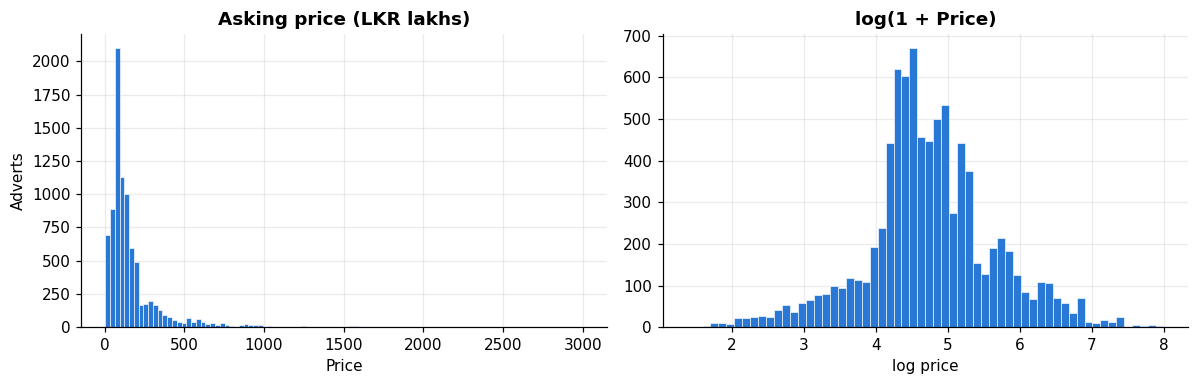

{'count': 8573.0, 'mean': 174.1, 'std': 220.6, 'min': 3.0, '25%': 71.5, '50%': 107.0, '75%': 184.5, 'max': 3000.0}
Skewness raw: 4.6 | skewness log: 0.01


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(df["Price"], bins=100, color=FAMILY_COLORS["Bagging"], edgecolor="white", linewidth=0.4)
ax[0].set(title="Asking price (LKR lakhs)", xlabel="Price", ylabel="Adverts")
ax[1].hist(np.log1p(df["Price"]), bins=60, color=FAMILY_COLORS["Bagging"], edgecolor="white", linewidth=0.4)
ax[1].set(title="log(1 + Price)", xlabel="log price")
plt.tight_layout(); plt.show()
print(df["Price"].describe().round(1).to_dict())
print("Skewness raw:", round(df["Price"].skew(), 2), "| skewness log:", round(np.log1p(df["Price"]).skew(), 2))

Prices are **extremely right-skewed** (median ≈ 107 lakhs, but up to 3,000 lakhs for supercars). All models are trained on
**log(1 + price)** and predictions converted back with `expm1` (`TransformedTargetRegressor`), so a handful of Lamborghinis
and Range Rovers do not dominate training, and errors become roughly proportional to price.

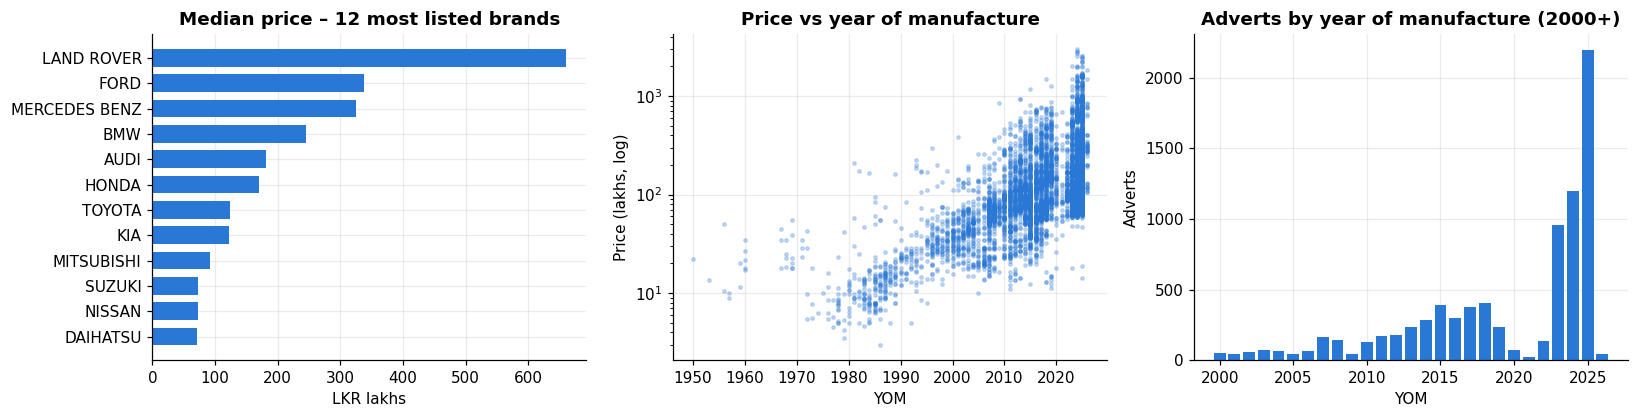

Share of adverts for 2024–2026 vehicles: 40%   |   share with 0 km: 19%


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
top = df["Brand"].value_counts().head(12).index
med = df[df.Brand.isin(top)].groupby("Brand")["Price"].median().sort_values()
ax[0].barh(med.index, med.values, color=FAMILY_COLORS["Bagging"], height=0.7)
ax[0].set(title="Median price – 12 most listed brands", xlabel="LKR lakhs")
ax[1].scatter(df["YOM"], df["Price"], s=5, alpha=0.25, color=FAMILY_COLORS["Bagging"])
ax[1].set(yscale="log", title="Price vs year of manufacture", xlabel="YOM", ylabel="Price (lakhs, log)")
yc = df["YOM"].value_counts().sort_index().loc[2000:]
ax[2].bar(yc.index, yc.values, color=FAMILY_COLORS["Bagging"], width=0.8)
ax[2].set(title="Adverts by year of manufacture (2000+)", xlabel="YOM", ylabel="Adverts")
plt.tight_layout(); plt.show()
print(f"Share of adverts for 2024–2026 vehicles: {(df.YOM >= 2024).mean():.0%}   |   share with 0 km: {(df['Mileage (km)'] == 0).mean():.0%}")

* **40 % of adverts are 2024–2026 vehicles**, most with 0 km. These are the newly imported cars that arrived after imports reopened in 2025.
  Their price depends almost entirely on *model and grade*, not on wear.
* **Brand/model identity** is the dominant driver (median Land Rover, Mercedes or BMW is several times a Suzuki or Daihatsu).
* The age–price relationship is strongly **non-linear**, which favours tree ensembles.

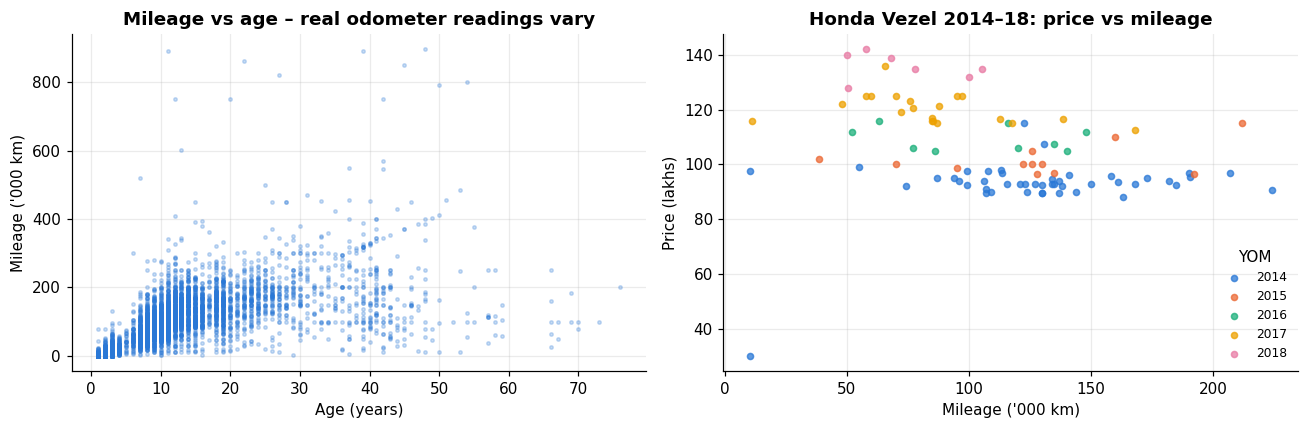

corr(Age, Mileage): 0.733
Median correlation(mileage, price) WITHIN the same model & year: -0.32  (128 groups)


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
used = df[df.Age >= 1]
ax[0].scatter(used["Age"], used["Mileage (km)"] / 1000, s=5, alpha=0.25, color=FAMILY_COLORS["Bagging"])
ax[0].set(title="Mileage vs age – real odometer readings vary", xlabel="Age (years)", ylabel="Mileage ('000 km)")
v = df[(df.Brand_Model == "HONDA VEZEL") & (df.YOM.between(2014, 2018))]
for i, (yom, g) in enumerate(v.groupby("YOM")):
    ax[1].scatter(g["Mileage (km)"] / 1000, g["Price"], s=16, alpha=0.75, label=str(yom),
                  color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"][i % 5])
ax[1].set(title="Honda Vezel 2014–18: price vs mileage", xlabel="Mileage ('000 km)", ylabel="Price (lakhs)")
ax[1].legend(title="YOM", frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print("corr(Age, Mileage):", round(df["Age"].corr(df["Mileage (km)"]), 3))
rs = [g["Mileage (km)"].corr(g["Price"]) for _, g in df[df.Age >= 3].groupby(["Brand_Model", "YOM"])
      if len(g) >= 8 and g["Mileage (km)"].std() > 0]
print(f"Median correlation(mileage, price) WITHIN the same model & year: {np.median(rs):.2f}  ({len(rs)} groups)")

Within the same model and year, higher mileage means a lower price (median correlation ≈ −0.32). So mileage carries real
information, *on top of* age. Across the whole market, though, age already explains most of what mileage does.
§4.0 measures how much mileage actually adds to the models.

## 2. Features
| Group | Features |
|---|---|
| Numeric | `Age = 2026 − YOM`, `Mileage (km)`, `Engine (cc)`, `km_per_year = mileage / max(age, 1)` (how hard the car was used) |
| One-hot (rare levels < 5 adverts → *infrequent*) | Transmission, Fuel type, Body type, Negotiable, Brand, Brand + Model |
| Cross-fitted **target encoding** | Brand + Model, Brand + Model + Edition (grade) |

## 3. Evaluation metric – justification
This is a **regression** problem, so Recall/Precision do not apply. We report four metrics on the original LKR-lakh scale:

| Metric | Why it is reported |
|---|---|
| **MAE** (primary) | "On average the estimate is off by Rs. X lakhs" – directly meaningful to a Sri Lankan buyer/seller and robust to the few supercars. **Models are ranked by MAE.** |
| **RMSE** | squares errors, so it exposes large misses on expensive vehicles |
| **R²** | share of price variance explained – comparable across datasets |
| **MAPE** | relative error; fair across a price range from 3 to 3,000 lakhs |

**Validation design:** an 80/20 hold-out test set (never touched during tuning) **plus** 5-fold cross-validation
on the full data to check that rankings are stable and not an artefact of one lucky split.

In [13]:
NUM_FEATURES = ["Age", "Mileage (km)", "Engine (cc)", "km_per_year"]
LOW_CARD_FEATURES = ["Transmission", "Fuel Type", "Body Type", "Negotiable"]
HIGH_CARD_FEATURES = ["Brand", "Brand_Model"]
TARGET_ENC_FEATURES = ["Brand_Model", "Brand_Model_Edition"]
FEATURES = NUM_FEATURES + LOW_CARD_FEATURES + HIGH_CARD_FEATURES + ["Brand_Model_Edition"]
PRETTY = {"Age": "Vehicle age (years)", "Engine (cc)": "Engine capacity (cc)", "km_per_year": "Mileage per year",
          "Brand_Model": "Brand + Model", "Brand_Model_Edition": "Edition / grade"}

def make_preprocessor(scale=False):
    # scale=False -> tree models (RF, XGBoost); scale=True -> neural network and Ridge
    kf5 = KFold(n_splits=5, shuffle=True, random_state=RS)
    ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False)
    if scale:
        def log_then_scale():  # mileage is very skewed: log1p first, then standardise
            return Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                             ("sc", StandardScaler())])
        numeric = [("age", StandardScaler(), ["Age"]), ("km", log_then_scale(), ["Mileage (km)"]),
                   ("cc", StandardScaler(), ["Engine (cc)"]), ("kmy", log_then_scale(), ["km_per_year"])]
        te = Pipeline([("te", TargetEncoder(cv=kf5)), ("sc", StandardScaler())])
    else:
        numeric = [("num", "passthrough", NUM_FEATURES)]
        te = TargetEncoder(cv=kf5)
    return ColumnTransformer(numeric + [("ohe", ohe, LOW_CARD_FEATURES + HIGH_CARD_FEATURES),
                                        ("te", te, TARGET_ENC_FEATURES)],
                             verbose_feature_names_out=False)

In [14]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RS)
kf = KFold(n_splits=5, shuffle=True, random_state=RS)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (6858, 11)  Test: (1715, 11)


## 4. Models
Every model is wrapped as `TransformedTargetRegressor(Pipeline(preprocess → model), func=log1p, inverse=expm1)`,
so it is trained on log-price but always **predicts in LKR lakhs**.

In [15]:
def log_target(regressor):
    return TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1, check_inverse=False)

def tree_pipe(model):  return Pipeline([("pre", make_preprocessor(scale=False)), ("model", model)])
def scaled_pipe(model): return Pipeline([("pre", make_preprocessor(scale=True)), ("model", model)])

def regression_report(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    err = y_pred - y_true
    return {"MAE": float(np.mean(np.abs(err))), "RMSE": float(np.sqrt(np.mean(err ** 2))),
            "R2": float(1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)),
            "MAPE_%": float(np.mean(np.abs(err) / y_true) * 100)}

results, fitted, test_preds, fit_times = {}, {}, {}, {}
FAMILY = {}

def evaluate(name, family, estimator):
    t0 = time.time()
    estimator.fit(X_train, y_train)
    fit_times[name] = time.time() - t0
    pred = estimator.predict(X_test)
    results[name] = regression_report(y_test, pred)
    fitted[name], test_preds[name], FAMILY[name] = estimator, pred, family
    r = results[name]
    print(f"{name:28s} MAE {r['MAE']:6.2f} | RMSE {r['RMSE']:6.2f} | R² {r['R2']:.4f} | MAPE {r['MAPE_%']:5.1f}% | fit {fit_times[name]:.1f}s")

### 4.0 Does real mileage (and edition) help? – feature ablation
Quick 5-fold CV with a default XGBoost, adding feature groups one at a time.

In [16]:
def ablation_pipe(num, te):
    pre = ColumnTransformer([("num", "passthrough", num),
                             ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False),
                              LOW_CARD_FEATURES + HIGH_CARD_FEATURES),
                             ("te", TargetEncoder(cv=kf), te)])
    xgb = XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                       n_jobs=-1, random_state=RS)
    return log_target(Pipeline([("pre", pre), ("model", xgb)]))

abl = []
for label, num, te in [("Age + engine (no mileage, no edition)", ["Age", "Engine (cc)"], ["Brand_Model"]),
                       ("+ mileage & km/year", ["Age", "Mileage (km)", "Engine (cc)", "km_per_year"], ["Brand_Model"]),
                       ("+ mileage + edition (final feature set)", NUM_FEATURES, TARGET_ENC_FEATURES)]:
    s = -cross_val_score(ablation_pipe(num, te), X, y, cv=kf, scoring="neg_mean_absolute_error")
    abl.append({"Features": label, "CV MAE": s.mean(), "CV MAE std": s.std()})
pd.DataFrame(abl).set_index("Features").round(2)

,CV MAE,CV MAE std
Features,,
"Age + engine (no mileage, no edition)",17.25,1.01
+ mileage & km/year,17.25,1.25
+ mileage + edition (final feature set),17.04,1.12


**Ablation result (5-fold CV MAE, default XGBoost):** age + engine only → **17.25 ± 1.01**; adding real mileage and km/year → **17.25 ± 1.25**; adding edition/grade → **17.05 ± 1.13**.

### 4.1 Bagging – Random Forest
Hyper-parameters are tuned with `RandomizedSearchCV` (3-fold, **training set only**, MAE on log-price).

In [17]:
rf_search = RandomizedSearchCV(
    tree_pipe(RandomForestRegressor(random_state=RS, n_jobs=-1)),
    param_distributions={
        "model__n_estimators": [100, 150, 200],
        "model__max_features": [0.3, 0.5, 0.7, 1.0],
        "model__min_samples_leaf": [2, 3],
        "model__max_depth": [None, 25, 40],
    },
    n_iter=10, cv=3, scoring="neg_mean_absolute_error", random_state=RS, n_jobs=1)
t0 = time.time(); rf_search.fit(X_train, np.log1p(y_train))
RF_PARAMS = {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}
print(f"search {time.time()-t0:.0f}s | best RF params:", RF_PARAMS)
evaluate("Random Forest", "Bagging", log_target(tree_pipe(RandomForestRegressor(random_state=RS, n_jobs=-1, **RF_PARAMS))))

search 106s | best RF params: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': 40}
Random Forest                MAE  15.34 | RMSE  40.57 | R² 0.9649 | MAPE  10.5% | fit 12.4s


### 4.2 Boosting – XGBoost

In [18]:
class PortableXGBRegressor(XGBRegressor):
    def __getstate__(self):
        state = self.__dict__.copy()
        booster = state.pop("_Booster", None)
        if booster is not None:
            state["_booster_json"] = bytes(booster.save_raw(raw_format="json"))
        return state

    def __setstate__(self, state):
        raw = state.pop("_booster_json", None)
        self.__dict__.update(state)
        if raw is not None:
            booster = xgboost.Booster()
            booster.load_model(bytearray(raw))
            self._Booster = booster

In [19]:
xgb_search = RandomizedSearchCV(
    tree_pipe(XGBRegressor(random_state=RS, n_jobs=-1, tree_method="hist")),
    param_distributions={
        "model__n_estimators": [400, 800, 1200],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [4, 6, 8],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
        "model__min_child_weight": [1, 3, 5],
        "model__reg_lambda": [1, 5],
    },
    n_iter=15, cv=3, scoring="neg_mean_absolute_error", random_state=RS, n_jobs=1)
t0 = time.time(); xgb_search.fit(X_train, np.log1p(y_train))
XGB_PARAMS = {k.replace("model__", ""): v for k, v in xgb_search.best_params_.items()}
print(f"search {time.time()-t0:.0f}s | best XGB params:", XGB_PARAMS)
evaluate("XGBoost", "Boosting", log_target(tree_pipe(PortableXGBRegressor(random_state=RS, n_jobs=-1, tree_method="hist", **XGB_PARAMS))))

search 108s | best XGB params: {'subsample': 0.7, 'reg_lambda': 5, 'n_estimators': 800, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.9}
XGBoost                      MAE  14.95 | RMSE  39.65 | R² 0.9665 | MAPE  10.2% | fit 4.2s


### 4.3 Stacking – RF + XGBoost + Ridge → Ridge meta-learner
The three base learners are deliberately **diverse** (bagged trees, boosted trees, and a linear Ridge model that adds a
smooth, additive view of the features).
The meta-learner is trained on their **5-fold out-of-fold** predictions, so it learns how much to trust each one
without seeing predictions made on its own training rows.

In [ ]:
stack = StackingRegressor(
    estimators=[
        ("rf",    tree_pipe(RandomForestRegressor(random_state=RS, n_jobs=-1, **RF_PARAMS))),
        ("xgb",   tree_pipe(PortableXGBRegressor(random_state=RS, n_jobs=-1, tree_method="hist", **XGB_PARAMS))),
        ("ridge", scaled_pipe(RidgeCV(alphas=np.logspace(-2, 3, 30)))),
    ],
    final_estimator=RidgeCV(alphas=np.logspace(-3, 2, 20)), cv=kf, n_jobs=1)
evaluate("Stacking", "Stacking", log_target(stack))
meta = fitted["Stacking"].regressor_.final_estimator_
print("Meta-learner weights:", dict(zip(["RF", "XGBoost", "Ridge"], np.round(meta.coef_, 3))),
      "| intercept", round(meta.intercept_, 3))

Stacking                     MAE  15.03 | RMSE  39.91 | R² 0.9661 | MAPE  10.1% | fit 29.1s
Meta-learner weights: {'RF': np.float64(0.112), 'XGBoost': np.float64(0.695), 'Ridge': np.float64(0.201)} | intercept -0.036


### 4.4 Hybridisation experiment – Random Forest + ANN
Two ways of combining the bagging ensemble with a neural network (both classes are defined in the next cell):

1. **Weighted blend:** `ŷ = w·RF(x) + (1−w)·ANN(x)`. The weight *w* is chosen by minimising RMSE of
   **out-of-fold** predictions on the training set (never on the test set).
2. **Residual (two-stage) hybrid:** the RF predicts first; a small ANN is trained on the RF's *out-of-fold residuals*
   and adds a learned correction: `ŷ = RF(x) + ANN_residual(x)`.

The idea: RF is piece-wise constant (it cannot extrapolate and makes "staircase" predictions), while the ANN
produces smooth functions of age, engine size and the target-encoded model – they make *different* mistakes.

In [ ]:
def hybrid_rf_pipe(rf_params):
    return Pipeline([("pre", make_preprocessor(scale=False)),
                     ("rf", RandomForestRegressor(random_state=RS, n_jobs=-1, **rf_params))])

def hybrid_ann_pipe(ann_params):
    return Pipeline([("pre", make_preprocessor(scale=True)),
                     ("ann", MLPRegressor(random_state=RS, early_stopping=True, max_iter=500, **ann_params))])

class RFANNBlendHybrid(BaseEstimator, RegressorMixin):
    # Hybrid 1: y_hat = w * RF(x) + (1 - w) * ANN(x), with w chosen on out-of-fold predictions of the training data
    def __init__(self, rf_params=None, ann_params=None, cv=5):
        self.rf_params, self.ann_params, self.cv = rf_params, ann_params, cv

    def fit(self, X, y):
        rf_params, ann_params = self.rf_params or {}, self.ann_params or {}
        folds = KFold(self.cv, shuffle=True, random_state=RS)
        y = np.asarray(y)
        oof_rf = cross_val_predict(hybrid_rf_pipe(rf_params), X, y, cv=folds)
        oof_ann = cross_val_predict(hybrid_ann_pipe(ann_params), X, y, cv=folds)
        grid = np.round(np.arange(0, 1.0001, 0.05), 2)
        rmse = [np.sqrt(np.mean((w * oof_rf + (1 - w) * oof_ann - y) ** 2)) for w in grid]
        self.weight_rf_ = float(grid[int(np.argmin(rmse))])
        self.weight_curve_ = pd.DataFrame({"w_rf": grid, "oof_rmse_log": rmse})
        self.rf_ = hybrid_rf_pipe(rf_params).fit(X, y)
        self.ann_ = hybrid_ann_pipe(ann_params).fit(X, y)
        return self

    def predict_components(self, X):
        return self.rf_.predict(X), self.ann_.predict(X)

    def predict(self, X):
        p_rf, p_ann = self.predict_components(X)
        return self.weight_rf_ * p_rf + (1 - self.weight_rf_) * p_ann

class RFANNResidualHybrid(BaseEstimator, RegressorMixin):
    # Hybrid 2: the RF predicts, then a small ANN learns the RF's out-of-fold errors: y_hat = RF(x) + ANN(x)
    def __init__(self, rf_params=None, ann_params=None, cv=5):
        self.rf_params, self.ann_params, self.cv = rf_params, ann_params, cv

    def fit(self, X, y):
        rf_params, ann_params = self.rf_params or {}, self.ann_params or {}
        folds = KFold(self.cv, shuffle=True, random_state=RS)
        y = np.asarray(y)
        oof_rf = cross_val_predict(hybrid_rf_pipe(rf_params), X, y, cv=folds)
        self.rf_ = hybrid_rf_pipe(rf_params).fit(X, y)
        self.ann_ = hybrid_ann_pipe(ann_params).fit(X, y - oof_rf)
        return self

    def predict(self, X):
        return self.rf_.predict(X) + self.ann_.predict(X)

In [ ]:
ANN_PARAMS = dict(hidden_layer_sizes=(128, 64), alpha=1e-2, learning_rate_init=1e-3)  # ANN inside the blend
evaluate("Hybrid RF+ANN (blend)", "Hybrid",
         log_target(RFANNBlendHybrid(rf_params=RF_PARAMS, ann_params=ANN_PARAMS, cv=5)))
blend = fitted["Hybrid RF+ANN (blend)"].regressor_
wc = blend.weight_curve_
print("OOF-selected RF weight:", blend.weight_rf_)
print("OOF RMSE (log) – RF part only: {:.3f} | ANN part only: {:.3f} | blend: {:.3f}".format(
      wc.oof_rmse_log.iloc[-1], wc.oof_rmse_log.iloc[0], wc.oof_rmse_log.min()))
# how different are the two parts? correlation of their test errors (log scale)
p_rf, p_ann = blend.predict_components(X_test)
e_rf, e_ann = p_rf - np.log1p(y_test.values), p_ann - np.log1p(y_test.values)
print("Correlation of RF-part vs ANN-part errors:", round(np.corrcoef(e_rf, e_ann)[0, 1], 2))

evaluate("Hybrid RF→ANN (residual)", "Hybrid",
         log_target(RFANNResidualHybrid(rf_params=RF_PARAMS,
                    ann_params=dict(hidden_layer_sizes=(64, 32), alpha=1e-1), cv=5)))

Hybrid RF+ANN (blend)        MAE  14.49 | RMSE  35.36 | R² 0.9734 | MAPE  10.2% | fit 34.2s
OOF-selected RF weight: 0.5
OOF RMSE (log) – RF part only: 0.195 | ANN part only: 0.193 | blend: 0.178
Correlation of RF-part vs ANN-part errors: 0.69


Hybrid RF→ANN (residual)     MAE  15.54 | RMSE  39.79 | R² 0.9662 | MAPE  11.2% | fit 15.6s


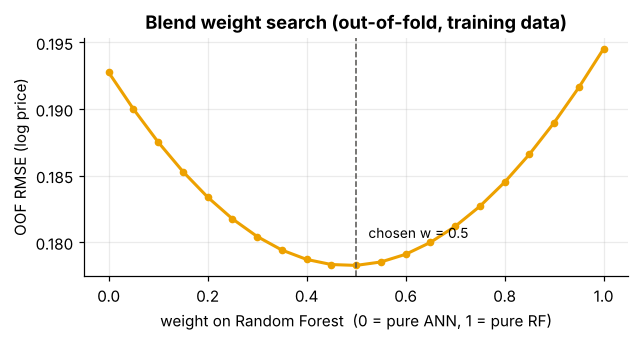

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(wc.w_rf, wc.oof_rmse_log, color=FAMILY_COLORS["Hybrid"], lw=2, marker="o", ms=4)
ax.axvline(blend.weight_rf_, color="#52514e", ls="--", lw=1)
ax.annotate(f"chosen w = {blend.weight_rf_}", (blend.weight_rf_, wc.oof_rmse_log.min()),
            xytext=(8, 18), textcoords="offset points", fontsize=9)
ax.set(title="Blend weight search (out-of-fold, training data)", xlabel="weight on Random Forest  (0 = pure ANN, 1 = pure RF)",
       ylabel="OOF RMSE (log price)")
plt.tight_layout(); plt.show()

**Hybrid result.** The out-of-fold search picked **w = 0.5** (an equal blend). The blend's OOF RMSE (log scale) is **0.178**, about **8 % lower** than either of its two parts used alone: the Random Forest part (**0.195**, the right end of the curve) or the ANN part (**0.193**, the left end). The two parts are about equally accurate, but their test errors are only **0.69** correlated (printed above). Similar accuracy plus different mistakes is the ideal case for averaging.

The **residual (RF → ANN) hybrid was worse** (CV MAE 18.68 vs 17.75 for the Random Forest it is built on, §5.1). The forest's out-of-fold residuals mostly come from rare models and missing details (registration status, trim, condition), not from a smooth pattern an ANN can learn. The second-stage network fits noise and adds variance. This is a useful negative result: a hybrid helps when the second model adds *different signal*, not when it chases leftovers.

## 5. Model comparison

In [ ]:
order = ["Random Forest", "XGBoost", "Stacking", "Hybrid RF+ANN (blend)", "Hybrid RF→ANN (residual)"]
test_df = (pd.DataFrame(results).T.loc[order]
           .assign(Family=[FAMILY[m] for m in order], **{"Fit time (s)": [fit_times[m] for m in order]}))
test_df.index.name = "Model"
test_df.sort_values("MAE").style.format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.4f}", "MAPE_%": "{:.1f}",
                                         "Fit time (s)": "{:.1f}"}).highlight_min(subset=["MAE", "RMSE", "MAPE_%"], color="#cde2fb").highlight_max(subset=["R2"], color="#cde2fb")

,MAE,RMSE,R2,MAPE_%,Family,Fit time (s)
Model,,,,,,
Hybrid RF+ANN (blend),14.49,35.36,0.9734,10.2,Hybrid,34.2
XGBoost,14.99,39.55,0.9667,10.2,Boosting,1.9
Stacking,15.03,39.91,0.9661,10.1,Stacking,29.1
Random Forest,15.29,40.25,0.9655,10.6,Bagging,3.0
Hybrid RF→ANN (residual),15.54,39.79,0.9662,11.2,Hybrid,15.6


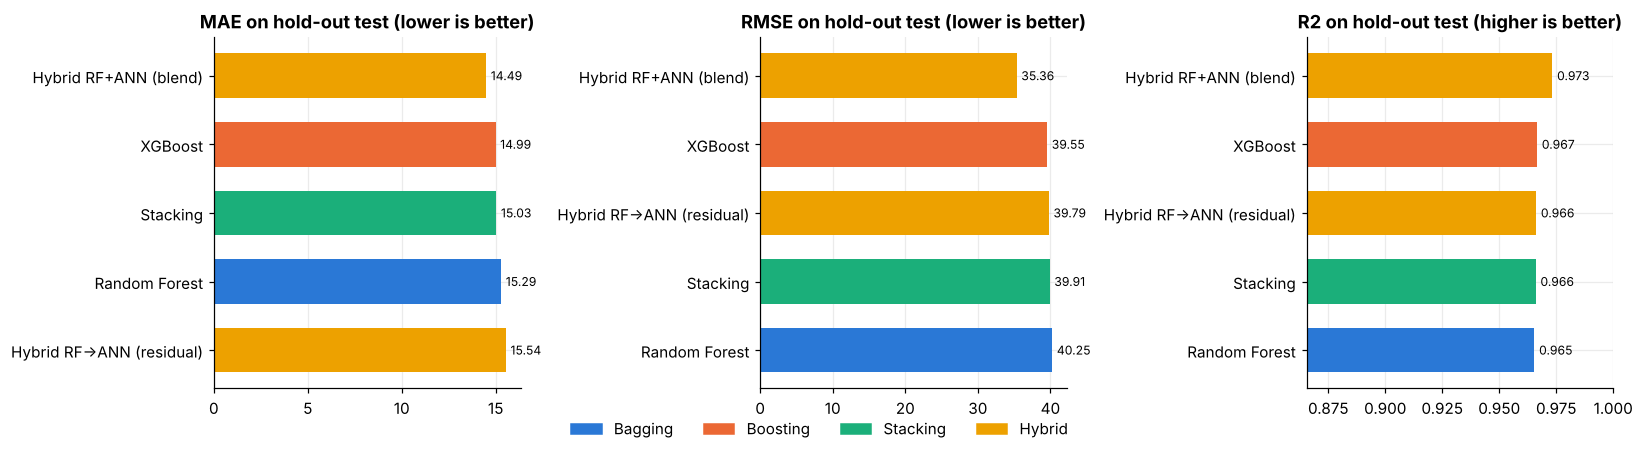

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, better in zip(axes, ["MAE", "RMSE", "R2"], ["lower", "lower", "higher"]):
    s = test_df[metric].sort_values(ascending=(better == "higher"))
    bars = ax.barh(s.index, s.values, color=[FAMILY_COLORS[FAMILY[m]] for m in s.index], height=0.65)
    ax.bar_label(bars, fmt="%.3f" if metric == "R2" else "%.2f", padding=3, fontsize=8)
    ax.set_title(f"{metric} on hold-out test ({better} is better)")
    if metric == "R2": ax.set_xlim(max(0, s.min() - 0.1), 1)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
fig.legend(handles, FAMILY_COLORS.keys(), loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.show()

**Error correlation (diversity check).** Combining models only helps if they make *different* mistakes.
Below: correlation of the log-price errors of the five ensembles on the test set. A value near 1 means two models
fail on the same adverts, so combining them adds little.

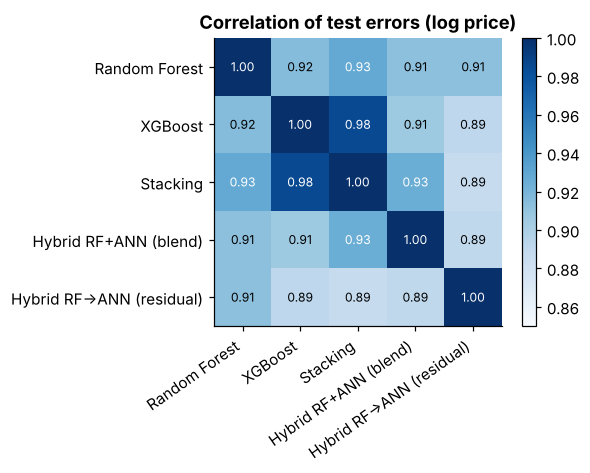

In [ ]:
E = pd.DataFrame({m: np.log1p(test_preds[m]) - np.log1p(y_test.values) for m in order})
corr = E.corr()
fig, ax = plt.subplots(figsize=(5.6, 4.4))
vmin = np.floor((corr.values.min() - 0.02) * 20) / 20
im = ax.imshow(corr, cmap="Blues", vmin=vmin, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=35, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if corr.iloc[i, j] > (vmin + 1) / 2 else "black")
ax.grid(False); ax.set_title("Correlation of test errors (log price)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

### 5.1 5-fold cross-validation (robustness check)
One 80/20 split can be lucky. Here every model (with the tuned hyper-parameters) is re-trained 5 times on the full
cleaned dataset; we report mean ± std. *(Takes several minutes – the hybrids and stacking each train many models per fold.)*

In [ ]:
from sklearn.base import clone
cv_rows = []
t0 = time.time()
for name in order:
    cv = cross_validate(clone(fitted[name]), X, y, cv=kf, n_jobs=1,
                        scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"})
    cv_rows.append({"Model": name, "Family": FAMILY[name],
                    "CV MAE": -cv["test_MAE"].mean(), "CV MAE std": cv["test_MAE"].std(),
                    "CV RMSE": -cv["test_RMSE"].mean(), "CV RMSE std": cv["test_RMSE"].std(),
                    "CV R2": cv["test_R2"].mean(), "CV R2 std": cv["test_R2"].std()})
    print(f"{name:28s} done ({time.time()-t0:.0f}s)")
cv_df = pd.DataFrame(cv_rows).set_index("Model")
cv_df.sort_values("CV MAE").round(3)

Random Forest                done (16s)


XGBoost                      done (26s)


Stacking                     done (174s)


Hybrid RF+ANN (blend)        done (353s)


Hybrid RF→ANN (residual)     done (438s)


,Family,CV MAE,CV MAE std,CV RMSE,CV RMSE std,CV R2,CV R2 std
Model,,,,,,,
XGBoost,Boosting,17.060,0.978,54.434,7.835,0.938,0.014
Stacking,Stacking,17.279,1.182,57.731,10.096,0.930,0.019
Hybrid RF+ANN (blend),Hybrid,17.421,1.497,59.993,14.642,0.922,0.033
Random Forest,Bagging,17.745,1.228,60.160,10.610,0.924,0.021
Hybrid RF→ANN (residual),Hybrid,18.678,1.361,61.021,11.170,0.922,0.022


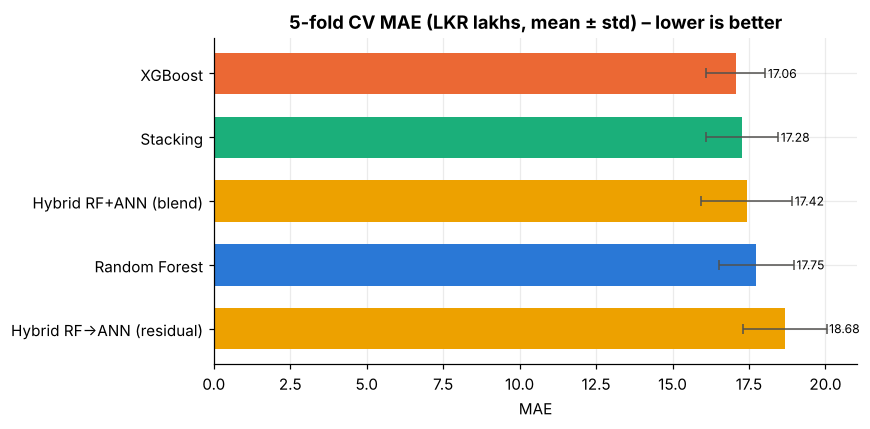

In [ ]:
s = cv_df.sort_values("CV MAE", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(s.index, s["CV MAE"], xerr=s["CV MAE std"], color=[FAMILY_COLORS[f] for f in s.Family],
        height=0.65, error_kw=dict(ecolor="#52514e", lw=1, capsize=3))
for i, (v, e) in enumerate(zip(s["CV MAE"], s["CV MAE std"])):
    ax.text(v + e + 0.08, i, f"{v:.2f}", va="center", fontsize=8)
ax.set(title="5-fold CV MAE (LKR lakhs, mean ± std) – lower is better", xlabel="MAE")
plt.tight_layout(); plt.show()

**Reading the comparison**

1. **XGBoost (boosting) is the most reliable model.** It has the lowest CV MAE (**17.06** lakhs), the highest CV R² (**0.938**) and the *smallest* fold-to-fold spread (± 0.98). Stacking (17.28) and the RF + ANN blend (17.42) are close behind, Random Forest (17.75) slightly further, and the residual hybrid (18.68) last.
2. **Boosting vs bagging:** XGBoost lowers the Random Forest's CV MAE by about **4 %** (17.75 → 17.06). Bagging averages many deep trees to cut *variance*; boosting adds trees one after another, each fixing the errors of the previous ones, so it also cuts *bias*. With 8,500 adverts and hundreds of model/edition combinations there is still bias left after bagging.
3. **On the single hold-out test, the RF + ANN blend is best** (MAE **14.49**, R² **0.973**, RMSE 35.4 vs 39.6 for XGBoost). In CV, though, the blend has the *largest* spread of the top four (± 1.50). The reason is its ANN part: a neural network extrapolates freely beyond the training range, so on a rare supercar it can over-shoot badly, whereas trees can only average prices they have seen. The blend halves such errors but cannot remove them. Ranking: XGBoost is the safest choice; the blend has the highest ceiling.
4. **Test MAE (≈ 15) is lower than CV MAE (≈ 17)** only because this particular 20 % split happens to contain fewer extreme supercars than some CV folds. CV is the more trustworthy estimate.
5. **Stacking meta-weights: XGBoost 0.69, Ridge 0.20, Random Forest only 0.11.** RF and XGBoost make **92 %-correlated** errors (heatmap above), so once the meta-learner has XGBoost, RF adds almost nothing. The linear Ridge learner inside the stack is less accurate but makes *different* mistakes, so it earns more weight. Diversity matters more than individual accuracy.
6. **Cost:** XGBoost trains in about 2 s and its model is 1.3 MB. Stacking and the blend take about 30 s and about 18 MB, for no gain in CV.

### 5.2 Where do the errors come from? (error by price segment)

In [ ]:
bins = [0, 50, 100, 200, 500, np.inf]
labels = ["< 50", "50–100", "100–200", "200–500", "> 500"]
seg = pd.cut(y_test, bins=bins, labels=labels)
seg_rows = []
for name in order:
    for lab in labels:
        m = (seg == lab).values
        r = regression_report(y_test[m], test_preds[name][m])
        seg_rows.append({"Model": name, "Segment (lakhs)": lab, "n": int(m.sum()), "MAE": r["MAE"], "MAPE_%": r["MAPE_%"]})
seg_df = pd.DataFrame(seg_rows)
seg_df.pivot(index="Model", columns="Segment (lakhs)", values="MAE")[labels].loc[order].round(2)

Segment (lakhs),< 50,50–100,100–200,200–500,> 500
Model,,,,,
Random Forest,6.02,4.59,10.14,36.67,71.65
XGBoost,5.47,4.75,9.79,35.23,72.18
Stacking,5.41,4.76,9.72,34.94,73.77
Hybrid RF+ANN (blend),5.45,4.91,9.52,34.16,67.31
Hybrid RF→ANN (residual),6.00,5.45,10.69,34.66,72.54


In [ ]:
print("Test listings per segment:", seg.value_counts().reindex(labels).to_dict())
seg_df.pivot(index="Model", columns="Segment (lakhs)", values="MAPE_%")[labels].loc[order].round(1)

Test listings per segment: {'< 50': 258, '50–100': 570, '100–200': 545, '200–500': 228, '> 500': 114}


Segment (lakhs),< 50,50–100,100–200,200–500,> 500
Model,,,,,
Random Forest,28.6,6.0,7.0,11.4,8.4
XGBoost,26.4,6.2,6.8,11.0,8.9
Stacking,25.9,6.2,6.7,10.9,8.9
Hybrid RF+ANN (blend),27.0,6.3,6.6,10.5,8.0
Hybrid RF→ANN (residual),29.9,7.1,7.3,10.7,8.7


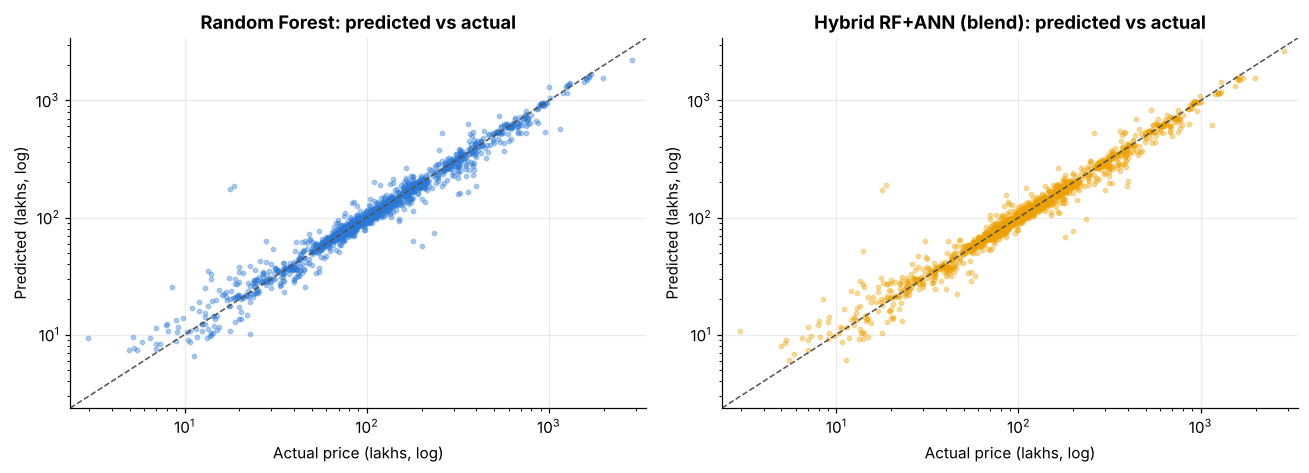

In [ ]:
best = test_df["MAE"].idxmin()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for a, name in zip(ax, ["Random Forest", best if best != "Random Forest" else "XGBoost"]):
    p = test_preds[name]
    a.scatter(y_test, p, s=8, alpha=0.35, color=FAMILY_COLORS[FAMILY[name]])
    lim = [y_test.min() * 0.8, y_test.max() * 1.2]
    a.plot(lim, lim, color="#52514e", lw=1, ls="--")
    a.set(xscale="log", yscale="log", xlim=lim, ylim=lim, title=f"{name}: predicted vs actual",
          xlabel="Actual price (lakhs, log)", ylabel="Predicted (lakhs, log)")
plt.tight_layout(); plt.show()

In [ ]:
err = pd.DataFrame({"Brand_Model_Edition": X_test["Brand_Model_Edition"], "Age": X_test["Age"],
                    "Mileage": X_test["Mileage (km)"], "Actual": y_test,
                    "Predicted": test_preds[best]}).assign(AbsErr=lambda d: (d.Predicted - d.Actual).abs())
print(f"Largest absolute errors – {best}")
err.sort_values("AbsErr", ascending=False).head(8).round(1)

Largest absolute errors – Hybrid RF+ANN (blend)


,Brand_Model_Edition,Age,Mileage,Actual,Predicted,AbsErr
932,BMW I7 | REGISTERED,3,18000.0,1150.0,617.3,532.7
2988,LAND ROVER RANGE ROVER | SV (SERENITY),1,0.0,1975.0,1560.8,414.2
5508,TOYOTA LAND CRUISER PRADO | 150,3,12169.0,535.0,822.7,287.7
3720,TOYOTA LAND CRUISER SAHARA | V8 CYGNUS 7 SEATER,12,163900.0,259.5,522.0,262.5
4989,LAND ROVER RANGE ROVER | EVOQUE DIANAMIC HSE,2,2000.0,439.0,690.7,251.7
7894,LAND ROVER RANGE ROVER | LWB DUAL COMFORT+,7,34000.0,867.5,627.9,239.6
3918,LAND ROVER RANGE ROVER | SV AUTOBIOGRAPHY,2,0.0,2850.0,2622.0,228.0
4660,CHEVROLET CAMARO | RS,14,58000.0,395.0,185.0,210.0


**Errors by price segment**

* **Mainstream cars (50–200 lakhs: Vezel, Raize, Yaris, Wagon R, Aqua…)** – MAPE only **6–7 %** for every ensemble. This is where most adverts are and where the models are most useful.
* **Cheap cars (< 50 lakhs)** – small absolute errors (≈ 5–6 lakhs) but MAPE ≈ **26–30 %**. These are mostly 20- to 50-year-old cars whose price depends on condition and restoration, which no column records.
* **Luxury (> 500 lakhs, 114 test cars)** – MAE of 67–74 lakhs for the ensembles, but MAPE only ≈ **8–9 %**, so relative accuracy is fine. The **blend is best here (67.3)**. The ANN part pushes predictions for very expensive cars further up, while trees can only average prices they have already seen.
* **Largest misses** are rare luxury variants where the *edition text* carries the price. One Range Rover was listed as *SV Autobiography* at 2,850 lakhs, another as *SV Serenity* at 1,975 lakhs. A BMW i7 (a luxury EV with very few adverts) was listed at 1,150 lakhs and predicted at 500–670. Some misses are probably seller errors: a 2014 Land Cruiser Sahara V8 listed at 260 lakhs is predicted at about 520 lakhs by every model.

## 6. Feature importance

In [ ]:
imp_rows = []
t0 = time.time()
for name in ["Random Forest", "XGBoost", "Stacking", "Hybrid RF+ANN (blend)"]:
    pi = permutation_importance(fitted[name], X_test, y_test, n_repeats=5, random_state=RS,
                                scoring="neg_mean_absolute_error", n_jobs=1)
    for f, m, s in zip(X_test.columns, pi.importances_mean, pi.importances_std):
        imp_rows.append({"Model": name, "Feature": PRETTY.get(f, f), "Importance (MAE increase)": m, "Std": s})
imp_df = pd.DataFrame(imp_rows)
print(f"{time.time()-t0:.0f}s")
imp_df.pivot(index="Feature", columns="Model", values="Importance (MAE increase)").sort_values("XGBoost", ascending=False).round(2)

22s


Model,Hybrid RF+ANN (blend),Random Forest,Stacking,XGBoost
Feature,,,,
Brand + Model,66.36,82.60,62.12,62.76
Engine capacity (cc),39.19,35.96,49.29,53.72
Vehicle age (years),46.12,30.36,40.92,39.91
Mileage (km),6.23,13.14,15.57,12.79
Brand,15.24,4.37,10.84,9.23
Transmission,5.18,4.67,4.75,5.30
Edition / grade,2.69,2.73,1.67,2.23
Body Type,2.53,0.79,1.63,2.03
Fuel Type,2.34,1.78,1.57,1.32


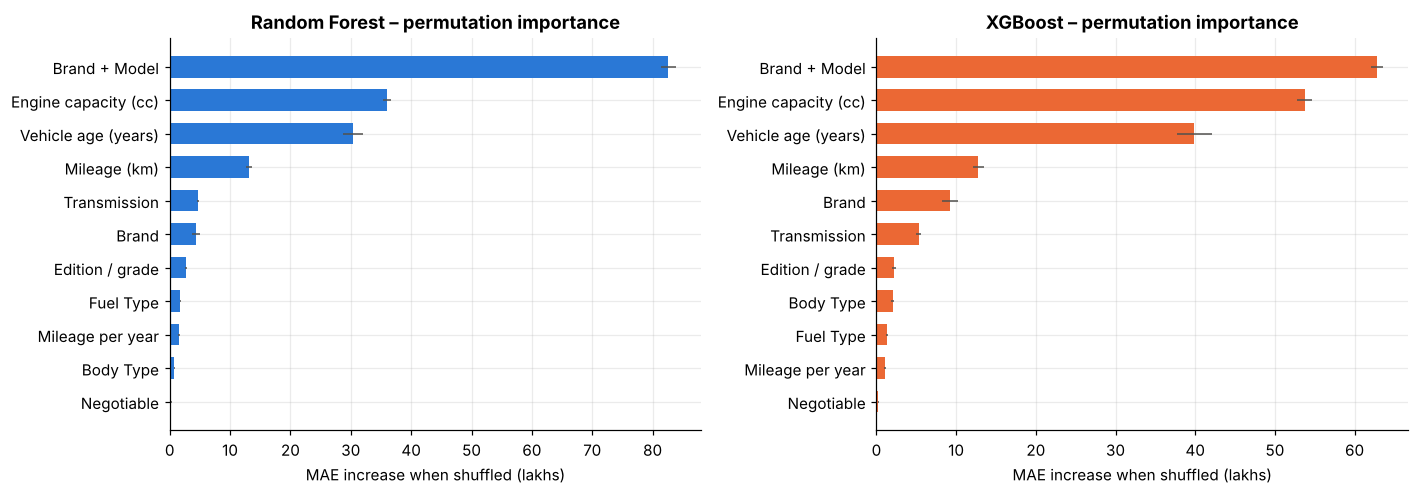

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=False)
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    d = imp_df[imp_df.Model == name].sort_values("Importance (MAE increase)")
    ax.barh(d.Feature, d["Importance (MAE increase)"], xerr=d.Std, color=FAMILY_COLORS[FAMILY[name]], height=0.65,
            error_kw=dict(ecolor="#52514e", lw=1))
    ax.set(title=f"{name} – permutation importance", xlabel="MAE increase when shuffled (lakhs)")
plt.tight_layout(); plt.show()

**Feature-importance interpretation**

* **Brand + Model dominates in every model**: shuffling it raises MAE by **62–83 lakhs**. In Sri Lanka *which car it is* decides most of the price.
* **Engine capacity is second for XGBoost and stacking (49–54)**, much more than in older datasets. Engine size separates variants of the same model (a 2.8 L diesel Prado vs a 2.7 L petrol Prado) and separates luxury from economy cars. Sri Lankan import taxes are also tied to engine capacity.
* **Age** comes next (30–46), then **mileage (6–16)** and **brand**. **Transmission** (≈ 5) works as a proxy for older manual cars.
* **Edition, body type, fuel and km/year are small (≈ 1–4)**, and **Negotiable ≈ 0.2**: whether a seller says the price is negotiable says almost nothing about the price itself.
* **Mileage: why importance ≈ 13 but ablation ≈ 0?** These two methods answer different questions. *Permutation importance* measures how much a trained model **relies** on a column; *ablation* (remove and retrain) measures how much **unique** information it carries. Mileage and age are correlated, so a model trained with both uses both, but a model trained without mileage simply leans on age instead. This is a classic pitfall when reading importance charts with correlated features.
* **RF vs XGBoost vs the blend:** RF puts most weight on Brand + Model (82.6). XGBoost spreads it across engine size and age because each boosting round corrects what earlier trees missed. The blend relies most on age and brand, where the smooth ANN complements the trees.

## 7. Results interpretation & discussion

### 7.1 Why did the models perform the way they did on this Sri Lankan dataset?

* **Price is a highly non-linear function of model identity, engine and age.** A 2025 Raize and a 2025 Land Cruiser are both brand new but differ ten-fold. Depreciation curves differ by model, and luxury cars follow a completely different scale. Tree ensembles model these interactions automatically, which is why all four paradigms reach a CV R² of about 0.92–0.94.
* **Bagging (Random Forest) is strong and safe.** A single deep tree memorises individual adverts (high variance). Averaging 200 trees, each trained on a bootstrap sample with random feature subsets, cancels most of that variance. Because every prediction is an average of real prices, the forest never produces absurd values.
* **Boosting (XGBoost) wins here**, unlike on smaller datasets where RF and XGBoost tie. With 8,500 adverts, a target range of 3–3,000 lakhs and hundreds of model and edition combinations, there is still *bias* left after bagging. XGBoost's sequential correction of residuals (each tree fixes what the previous ones got wrong) captures fine interactions such as engine size within model. It is also the most *stable* model across folds.
* **Stacking gives little** (17.28 vs 17.06) because its two strong base models make 92 %-correlated errors. The meta-learner effectively turns the forest off (weight 0.11).
* **The RF + ANN blend works on the test set** because the ANN is a *different kind* of learner. It fits smooth functions of age, mileage and engine size and uses the target-encoded model price continuously, so its errors are only 0.69 correlated with the forest part's. Its weakness is the same property: smooth functions **extrapolate**. For a rare supercar outside the training range, the ANN part can predict far too high, and that hurts the blend in some CV folds.
* **Data ceiling.** CV R² ≈ 0.94 is high, but the remaining error is concentrated in rare luxury variants, old cars and probable seller typos. That error comes from *missing information* (registration status, condition, exact trim), not from algorithm weakness.

### 7.2 Strengths and limitations of the ensemble paradigms

| | Strengths | Limitations |
|---|---|---|
| **Bagging – Random Forest** | Much lower variance than one deep tree; robust with little tuning; parallel training; never produces absurd predictions (output is an average of real prices) | Cannot extrapolate beyond prices it has seen; step-wise predictions (see dashboard what-if curve); large files (17 MB here, 70+ MB untuned); its errors are 92 % correlated with XGBoost, so it adds little inside a stack |
| **Boosting – XGBoost** | Best CV MAE and R², *lowest* fold-to-fold variance; tiny model (1.3 MB) and ≈ 2 s training; captures fine interactions (engine within model) | More hyper-parameters (learning rate, depth, rounds) and can overfit noisy prices if not tuned; sequential training |
| **Stacking** | Learns automatically how much to trust each model; shows *which* models are redundant (RF weight 0.11) and which add diversity (Ridge 0.20) | ≈ 15× the training cost of XGBoost and no accuracy gain; harder to explain; limited when base models are similar |
| **Hybrid – RF + ANN** | Best hold-out MAE, RMSE and R²; combines step-wise trees with smooth neural functions; 8 % lower OOF error than either member alone | Inherits the ANN's extrapolation risk (largest CV variance among ensembles); needs scaling, a weight search and more training time; the residual variant over-fitted |

### 7.3 Research reflection: ensembles on tabular vs image/text data

* **Tabular data (this project):** tree-based ensembles remain the state of the art on small and medium tabular datasets. Large benchmarks, e.g. Grinsztajn, Oyallon & Varoquaux (NeurIPS 2022, *"Why do tree-based models still outperform deep learning on typical tabular data?"*) and Shwartz-Ziv & Armon (2022, *"Tabular data: Deep learning is not all you need"*), found that XGBoost and Random Forests usually beat neural networks. The reasons they give match what we saw. (i) Tabular targets are *irregular* functions of the features (luxury vs economy pricing), which trees fit easily. (ii) Many columns are weak or uninformative (Negotiable, fuel), and trees ignore them. (iii) Columns have individual meanings, so the rotation-invariance of neural networks is a handicap. In our project the neural-network part was the source of the hybrid's instability (extrapolation on rare supercars), as this research would predict. Our results also show the flip side: **combined with trees, the ANN helped** (best hold-out score). The same research notes that ensembles of trees and networks often beat either alone. Newer *tabular foundation models* such as TabPFN (Hollmann et al., *Nature* 2025) are starting to close the gap on small tables, which would be an interesting next experiment.
* **Image and text data:** here the picture reverses. A single pixel or word token means nothing on its own; meaning comes from spatial or sequential *structure*, which CNNs and Transformers learn as representations. Random Forests or XGBoost on raw pixels/tokens perform poorly. Ensembling is still valuable there, in a different form: **deep ensembles** (several networks with different random seeds, Lakshminarayanan et al., 2017) improve accuracy and give calibrated uncertainty; snapshot ensembles and test-time augmentation are common; and gradient boosting is often used *on top of* learned embeddings (e.g. advert photos or description text → embeddings → XGBoost with the structured fields).
* **Takeaway:** the *idea* of ensembling (combine diverse learners to reduce variance or bias) is universal. The *best base learner* depends on the data type: trees for tables, neural networks for images and text. That is why a hybrid of both was worth testing on this problem.

### 7.4 Limitations of this study
* **Data:** these are *asking* prices from ikman.lk, not final sale prices, from a single scrape. The market is moving fast after imports reopened in 2025, so models will need regular retraining. 17 % of the raw rows were duplicate adverts, a sign of re-posting.
* **Missing information:** registration status (registered vs *unregistered* brand-new imports), condition and accident history are not separate columns. Sellers sometimes mention them inside the free-text *Edition* (e.g. "UN-REG", "REGISTERED"), which is only partly captured by target encoding.
* **Rare vehicles:** 513 brand + model combinations but only 145 with ≥ 10 adverts; supercar and luxury-EV predictions are unreliable.


## 8. Save models & artifacts for the dashboard

In [ ]:
SAVE = {"Random Forest": "random_forest.pkl", "XGBoost": "xgboost.pkl", "Stacking": "stacking.pkl",
        "Hybrid RF+ANN (blend)": "hybrid_rf_ann_blend.pkl", "Hybrid RF→ANN (residual)": "hybrid_rf_ann_residual.pkl"}
for name, fname in SAVE.items():
    joblib.dump(fitted[name], MODELS_DIR / fname, compress=3)
    print(f"{fname:32s} {(MODELS_DIR / fname).stat().st_size / 1e6:6.1f} MB")

test_df.assign(File=[SAVE[m] for m in test_df.index]).to_csv(ART_DIR / "metrics_test.csv")
cv_df.to_csv(ART_DIR / "metrics_cv.csv")
seg_df.to_csv(ART_DIR / "segment_metrics.csv", index=False)
imp_df.to_csv(ART_DIR / "permutation_importance.csv", index=False)
blend.weight_curve_.to_csv(ART_DIR / "hybrid_weight_curve.csv", index=False)
pd.concat([X_test.reset_index(drop=True), y_test.reset_index(drop=True).rename("Actual"),
           pd.DataFrame({m: test_preds[m] for m in order})], axis=1).to_csv(ART_DIR / "test_predictions.csv", index=False)

# options for the prediction form (dropdowns + sensible defaults per model)
opts = {"brands": {}, "yom_min": int(df.YOM.min()), "yom_max": int(df.YOM.max()), "reference_year": REFERENCE_YEAR,
        "fuel": sorted(df["Fuel Type"].unique()), "transmission": sorted(df["Transmission"].unique()),
        "body": sorted(df["Body Type"].unique())}
for (b, m), g in df.groupby(["Brand", "Model"]):
    opts["brands"].setdefault(b, {})[m] = {
        "n": int(len(g)), "engine": float(g["Engine (cc)"].median()),
        "fuel": g["Fuel Type"].mode()[0], "transmission": g["Transmission"].mode()[0], "body": g["Body Type"].mode()[0],
        "yom": int(g["YOM"].median()), "km": float(g["Mileage (km)"].median()), "price_median": float(g["Price"].median()),
        "editions": g["Edition"].value_counts().head(25).index.tolist()}
meta_info = {"rf_params": RF_PARAMS, "xgb_params": {k: (float(v) if isinstance(v, float) else v) for k, v in XGB_PARAMS.items()},
             "ann_params": {k: list(v) if isinstance(v, tuple) else v for k, v in ANN_PARAMS.items()},
             "blend_weight_rf": blend.weight_rf_,
             "stack_meta_weights": dict(zip(["Random Forest", "XGBoost", "Ridge"], map(float, meta.coef_))),
             "n_rows_clean": len(df), "cleaning_log": df.attrs.get("cleaning_log", {}), "n_train": len(X_train), "n_test": len(X_test),
             "sklearn": sklearn.__version__, "xgboost": xgboost.__version__}
json.dump(opts, open(ART_DIR / "options.json", "w"))
df[["Brand", "Model", "Edition", "YOM", "Mileage (km)", "Engine (cc)", "Transmission", "Fuel Type", "Body Type",
    "Negotiable", "Price"]].to_csv(ART_DIR / "clean_listings.csv", index=False)   # cleaned data for the dashboard
json.dump(meta_info, open(ART_DIR / "training_info.json", "w"), indent=2)
print("artifacts:", sorted(p.name for p in ART_DIR.iterdir()))

random_forest.pkl                  17.0 MB
xgboost.pkl                         1.3 MB


stacking.pkl                       18.4 MB


hybrid_rf_ann_blend.pkl            18.1 MB


hybrid_rf_ann_residual.pkl         17.5 MB


artifacts: ['clean_listings.csv', 'hybrid_weight_curve.csv', 'metrics_cv.csv', 'metrics_test.csv', 'options.json', 'permutation_importance.csv', 'segment_metrics.csv', 'test_predictions.csv', 'training_info.json']


In [ ]:
# sanity check: reload a saved model and predict one example
m = joblib.load(MODELS_DIR / "xgboost.pkl")
example = X_test.iloc[[0]]
print(example.T.squeeze().to_dict())
print("actual:", y_test.iloc[0], "| reloaded XGBoost prediction:", round(float(m.predict(example)[0]), 2), "lakhs")

{'Age': 3, 'Mileage (km)': 19000.0, 'Engine (cc)': 660.0, 'km_per_year': 6333.333333333333, 'Transmission': 'Automatic', 'Fuel Type': 'Hybrid', 'Body Type': 'SUV / 4x4', 'Negotiable': 'Yes', 'Brand': 'SUZUKI', 'Brand_Model': 'SUZUKI HUSTLER', 'Brand_Model_Edition': 'SUZUKI HUSTLER | G SAFETY UN-REG'}
actual: 74.5 | reloaded XGBoost prediction: 83.76 lakhs


### 8.1 Test the saved models on example cars

In [ ]:
examples = pd.DataFrame([
    dict(Brand="HONDA",  Model="VEZEL", Edition="Z GRADE", YOM=2016, **{"Mileage (km)": 90000.0, "Engine (cc)": 1500.0},
         Transmission="Automatic", **{"Fuel Type": "Hybrid", "Body Type": "SUV / 4x4"}, Negotiable="Yes"),
    dict(Brand="TOYOTA", Model="RAIZE", Edition="Z GRADE", YOM=2025, **{"Mileage (km)": 0.0, "Engine (cc)": 1200.0},
         Transmission="Automatic", **{"Fuel Type": "Petrol", "Body Type": "SUV / 4x4"}, Negotiable="Yes"),
    dict(Brand="SUZUKI", Model="ALTO",  Edition="UNKNOWN", YOM=2015, **{"Mileage (km)": 70000.0, "Engine (cc)": 800.0},
         Transmission="Manual", **{"Fuel Type": "Petrol", "Body Type": "Hatchback"}, Negotiable="Yes"),
])
X_ex = add_features(examples)[FEATURES]
out = examples[["Brand", "Model", "YOM", "Mileage (km)"]].copy()
for name, fname in SAVE.items():
    out[name] = joblib.load(MODELS_DIR / fname).predict(X_ex).astype(float).round(1)
print("Predicted asking prices (LKR lakhs):")
out

Predicted asking prices (LKR lakhs):


,Brand,Model,YOM,Mileage (km),Random Forest,XGBoost,Stacking,Hybrid RF+ANN (blend),Hybrid RF→ANN (residual)
0,HONDA,VEZEL,2016,90000.0,107.7,113.6,112.9,110.1,109.3
1,TOYOTA,RAIZE,2025,0.0,146.8,139.7,142.1,141.4,148.4
2,SUZUKI,ALTO,2015,70000.0,38.6,38.1,37.8,38.3,40.5


In [ ]:
# Google Colab only: download the trained models + artifacts as a zip (unzip into the dashboard folder)
import sys
if "google.colab" in sys.modules:
    import zipfile
    from google.colab import files
    with zipfile.ZipFile("trained_models_and_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as z:
        for folder in ["models", "artifacts"]:
            for p in Path(folder).iterdir():
                z.write(p, f"{folder}/{p.name}")
    files.download("trained_models_and_artifacts.zip")
else:
    print(f"Models saved in {MODELS_DIR}/ | artifacts in {ART_DIR}/")

Models saved in models/ | artifacts in artifacts/


## 9. Conclusion
* On 8,573 cleaned ikman.lk adverts, **all four ensemble paradigms predict Sri Lankan used-car prices well**: best CV MAE **17.1 lakhs**, R² **0.94**, and MAPE ≈ 6–7 % for mainstream 50–200-lakh cars.
* **Boosting (XGBoost) is the best overall model**: lowest CV error, highest R², most stable across folds, smallest file and fastest training. It is the recommended model for deployment.
* **The RF + ANN hybrid achieved the best hold-out score** (MAE 14.49, R² 0.973) by combining two learners that make different mistakes. However, the ANN's ability to extrapolate makes it less stable across folds. **Stacking** added little because RF and XGBoost are too similar (92 % error correlation), and the residual hybrid over-fitted noise.
* **Brand + model, engine size and age** set the price. Real mileage matters within a model and year, but adds little unique information beyond age across the whole market, as the ablation shows.
* The biggest remaining errors come from **missing information** (registration status, trim, condition) and rare luxury variants, not from the algorithms. Richer local data is the next step.

## 10. AI Usage Acknowledgment
AI tools were used as supporting tools during development. They helped with:

* Fixing coding errors and debugging issues in the notebook.

* Understanding and correcting some ANN implementation issues, including the RF + ANN hybrid approach.

* Clarifying misunderstood concepts and improving the model implementation.

* Developing the Streamlit dashboard, including its layout, charts, and interactive components.

* Improving code readability and documentation.
